# Student Performance Analysis
**SyntecxHub Data Analytics Project**

Author: KUDUKA APPASI VAISHNAVI

This notebook analyzes the supplied 100-student dataset. Note that attendance, study hours, class/section, and dates are not present in the supplied file.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'student_performance_100.csv'
df = pd.read_csv(DATA_PATH)
df.head()

,Student ID,Gender,Ethnicity,Parental Education,Test Preparation,Math Score,Reading Score,Writing Score
0,S001,Male,Group A,Bachelor's Degree,Completed,43,68,68
1,S002,Female,Group E,Associate's Degree,Completed,66,75,54
2,S003,Male,Group E,Some College,Completed,58,59,89
3,S004,Male,Group C,Associate's Degree,NaN,49,52,54
4,S005,Female,Group E,High School,NaN,45,54,35


## 1. Inspect and clean data

In [2]:
print('Shape:', df.shape)
display(df.info())
display(df.isna().sum().to_frame('Missing values'))
print('Exact duplicate rows:', df.duplicated().sum())
score_cols = ['Math Score', 'Reading Score', 'Writing Score']
for col in score_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.drop_duplicates().copy()
df[score_cols] = df[score_cols].clip(0, 100)
df['Overall Average'] = df[score_cols].mean(axis=1)
df['Performance Band'] = pd.cut(df['Overall Average'], [-0.01, 39.99, 59.99, 79.99, 100], labels=['Needs support', 'Developing', 'Proficient', 'Advanced'])
df.head()

Shape: (100, 8)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Student ID          100 non-null    str  
 1   Gender              100 non-null    str  
 2   Ethnicity           100 non-null    str  
 3   Parental Education  100 non-null    str  
 4   Test Preparation    41 non-null     str  
 5   Math Score          100 non-null    int64
 6   Reading Score       100 non-null    int64
 7   Writing Score       100 non-null    int64
dtypes: int64(3), str(5)
memory usage: 9.8 KB


None

,Missing values
Student ID,0
Gender,0
Ethnicity,0
Parental Education,0
Test Preparation,59
Math Score,0
Reading Score,0
Writing Score,0


Exact duplicate rows: 0


,Student ID,Gender,Ethnicity,Parental Education,Test Preparation,Math Score,Reading Score,Writing Score,Overall Average,Performance Band
0,S001,Male,Group A,Bachelor's Degree,Completed,43,68,68,59.666667,Developing
1,S002,Female,Group E,Associate's Degree,Completed,66,75,54,65.000000,Proficient
2,S003,Male,Group E,Some College,Completed,58,59,89,68.666667,Proficient
3,S004,Male,Group C,Associate's Degree,NaN,49,52,54,51.666667,Developing
4,S005,Female,Group E,High School,NaN,45,54,35,44.666667,Developing


## 2. Summary statistics

In [3]:
display(df[score_cols + ['Overall Average']].describe().round(2))
print('Mean score by subject:')
display(df[score_cols].mean().round(2).to_frame('Average score'))
print(f"Overall mean: {df['Overall Average'].mean():.2f}")
print(f"At or above 50 overall: {(df['Overall Average'] >= 50).sum()} students ({(df['Overall Average'] >= 50).mean()*100:.1f}%)")

,Math Score,Reading Score,Writing Score,Overall Average
count,100.00,100.00,100.00,100.00
mean,62.51,60.49,60.53,61.18
std,13.60,12.10,11.47,7.83
min,34.00,30.00,32.00,43.67
25%,52.75,51.00,53.00,55.25
50%,63.00,61.00,60.50,62.33
75%,72.25,68.25,68.00,66.08
max,97.00,90.00,89.00,78.00


Mean score by subject:


,Average score
Math Score,62.51
Reading Score,60.49
Writing Score,60.53


Overall mean: 61.18
At or above 50 overall: 90 students (90.0%)


## 3. Subject-wise bar chart

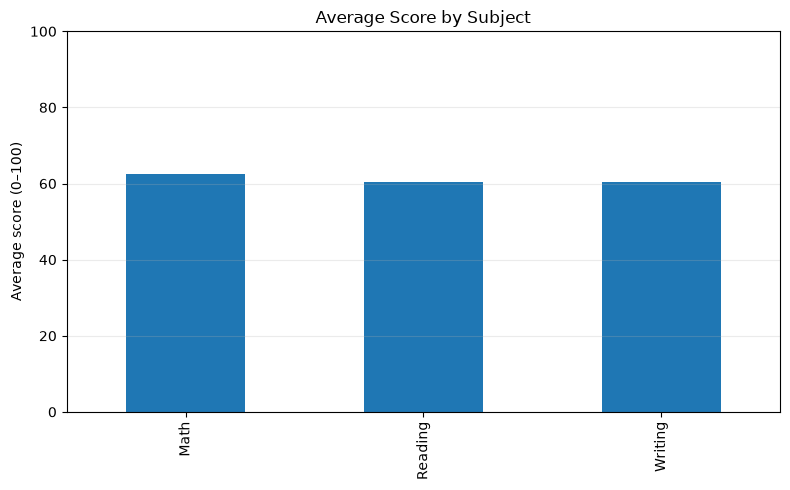

In [4]:
ax = df[score_cols].mean().rename(index=lambda x: x.replace(' Score', '')).plot(kind='bar', figsize=(8, 5), title='Average Score by Subject', ylim=(0, 100))
ax.set_ylabel('Average score (0–100)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Overall performance distribution

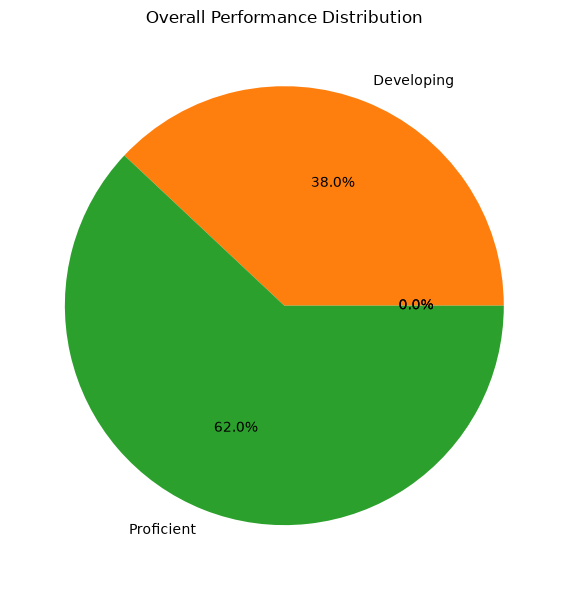

In [5]:
df['Performance Band'].value_counts().reindex(['Needs support', 'Developing', 'Proficient', 'Advanced'], fill_value=0).plot(kind='pie', autopct='%1.1f%%', figsize=(7, 6), title='Overall Performance Distribution', ylabel='')
plt.tight_layout()
plt.show()

## 5. Compare available groups

,Math Score,Reading Score,Writing Score,Overall Average
Gender,,,,
Female,63.58,60.83,59.38,61.26
Male,61.30,60.11,61.83,61.08


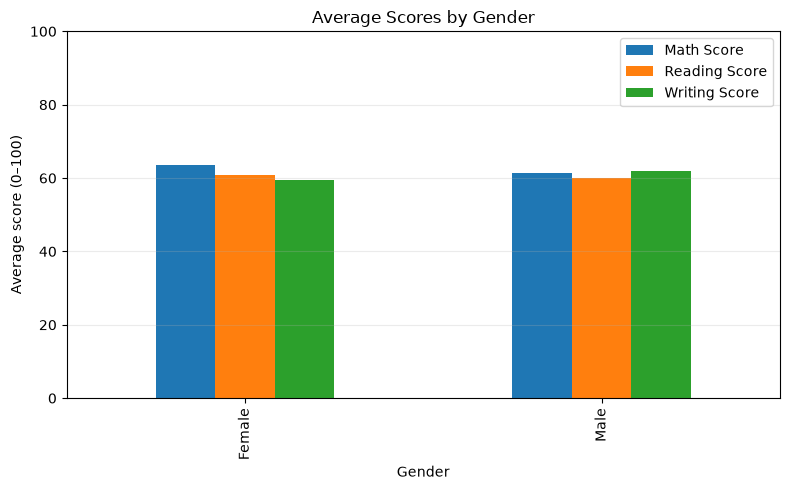

,Math Score,Reading Score,Writing Score,Overall Average
Ethnicity,,,,
Group A,63.77,62.04,63.27,63.03
Group B,62.00,57.50,62.29,60.60
Group C,60.62,59.54,59.96,60.04
Group D,65.35,63.06,56.47,61.63
Group E,61.00,59.47,59.84,60.11


,Math Score,Reading Score,Writing Score,Overall Average
Parental Education,,,,
Associate's Degree,61.39,60.30,56.83,59.51
Bachelor's Degree,63.06,64.06,62.24,63.12
High School,62.45,60.80,61.75,61.67
Master's Degree,58.46,59.54,59.54,59.18
Some College,70.54,56.77,62.62,63.31
Some High School,60.07,60.36,61.79,60.74


In [6]:
display(df.groupby('Gender')[score_cols + ['Overall Average']].mean().round(2))
ax = df.groupby('Gender')[score_cols].mean().plot(kind='bar', figsize=(8, 5), title='Average Scores by Gender', ylim=(0, 100))
ax.set_ylabel('Average score (0–100)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()
display(df.groupby('Ethnicity')[score_cols + ['Overall Average']].mean().round(2))
display(df.groupby('Parental Education')[score_cols + ['Overall Average']].mean().round(2))

## 6. Score relationships

,Math Score,Reading Score,Writing Score,Overall Average
Math Score,1.00,0.12,0.09,0.69
Reading Score,0.12,1.00,0.07,0.62
Writing Score,0.09,0.07,1.00,0.58
Overall Average,0.69,0.62,0.58,1.00


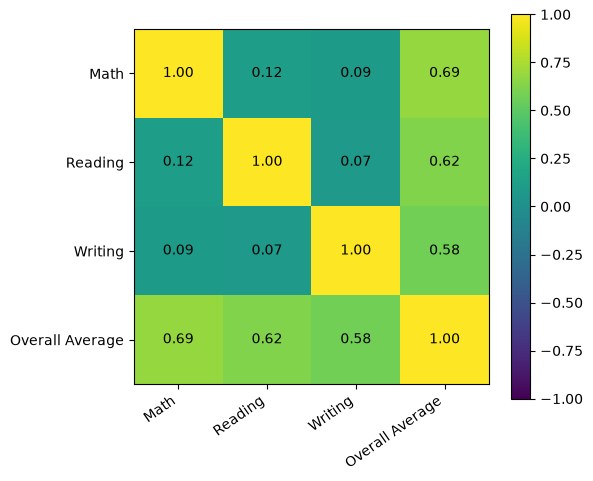

In [7]:
corr = df[score_cols + ['Overall Average']].corr()
display(corr.round(2))
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), [c.replace(' Score', '') for c in corr.columns], rotation=35, ha='right')
ax.set_yticks(range(len(corr.index)), [c.replace(' Score', '') for c in corr.index])
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 7. Data limitations and recommendations

- The dataset does not contain attendance, study hours, class/section, or assessment dates. Those requested relationships and trends cannot be evaluated with this file alone.
- Test Preparation is missing for many students; retain missing status as unknown rather than assuming non-completion.
- Use these results to identify questions for further investigation, not to claim that a demographic feature causes a score difference.
- Collect attendance and study-hour fields, class/section, and repeated assessment dates for richer analysis.
- Confirm official grading thresholds before using performance bands for decisions.